# 01 · Data understanding and exploratory analysis
UK STATS19 accidents 2005-2017. Produced by `python -m src.data_prep` and `python -m src.eda`.

In [1]:
import sys, json; sys.path.insert(0, '..')
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option('display.max_columns', 40, 'display.width', 160)
T = '../reports/tables/'; F = '../reports/figures/'
print(json.load(open(T+'dataset_summary.json')))
pd.read_csv(T+'cleaning_log.csv')

{'rows': 2046815, 'cols': 56, 'years': [2005, 2017], 'class_share': {'Slight': 0.8473, 'Serious': 0.1399, 'Fatal': 0.0129}}


,step,rows
0,raw file,2047256
1,drop duplicate accident ids,2047256
2,drop rows with missing latitude/longitude,2047081
3,keep coordinates inside UK bounding box,2047081
4,drop rows with missing time of day,2046925
5,keep valid speed limits (20-70 mph),2046852
6,drop 'Unallocated' urban/rural rows,2046815


Only a handful of rows are lost: every step logs its row count.

In [2]:
pd.read_csv(T+'missing_values_raw.csv', index_col=0)

,missing_pct
Carriageway_Hazards,98.15
Special_Conditions_at_Site,97.54
2nd_Road_Class,40.27
Junction_Control,36.20
LSOA_of_Accident_Location,4.52
2nd_Road_Number,0.90
Road_Surface_Conditions,0.14
Did_Police_Officer_Attend_Scene_of_Accident,0.08
Longitude,0.02
Location_Northing_OSGR,0.02


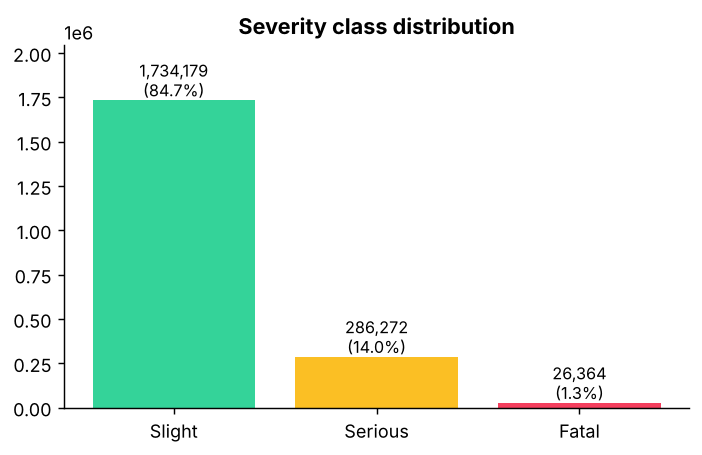

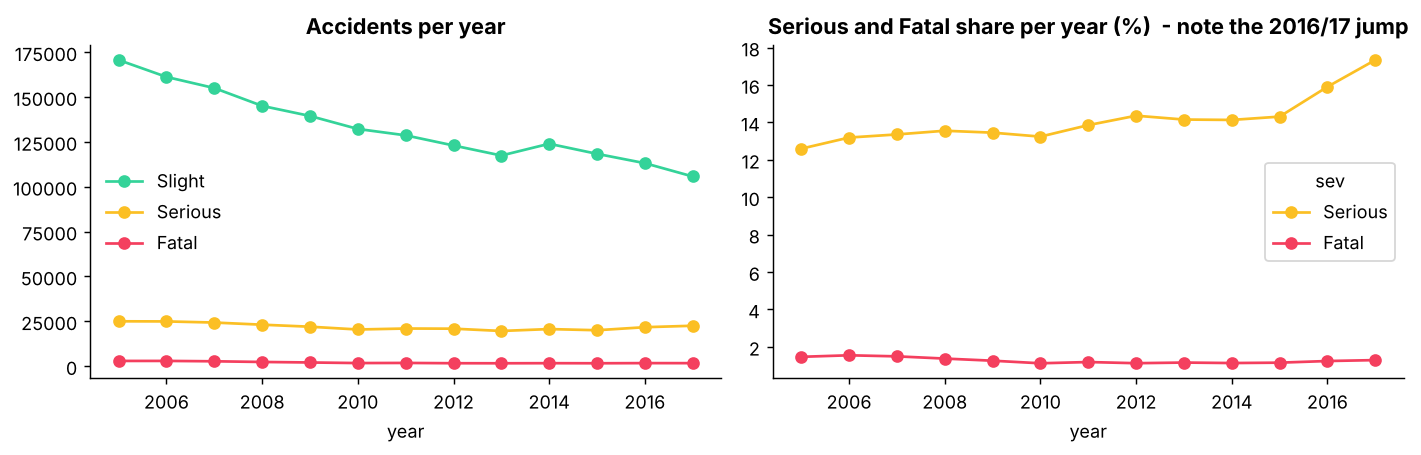

In [3]:
display(Image(F+'01_class_distribution.png')); display(Image(F+'05_yearly_trend.png'))

**Reading the plots.** 85% of accidents are Slight, and the Serious+Fatal share jumps in 2016-17, a distribution shift we handle with calibration and decision scales fitted on 2015.

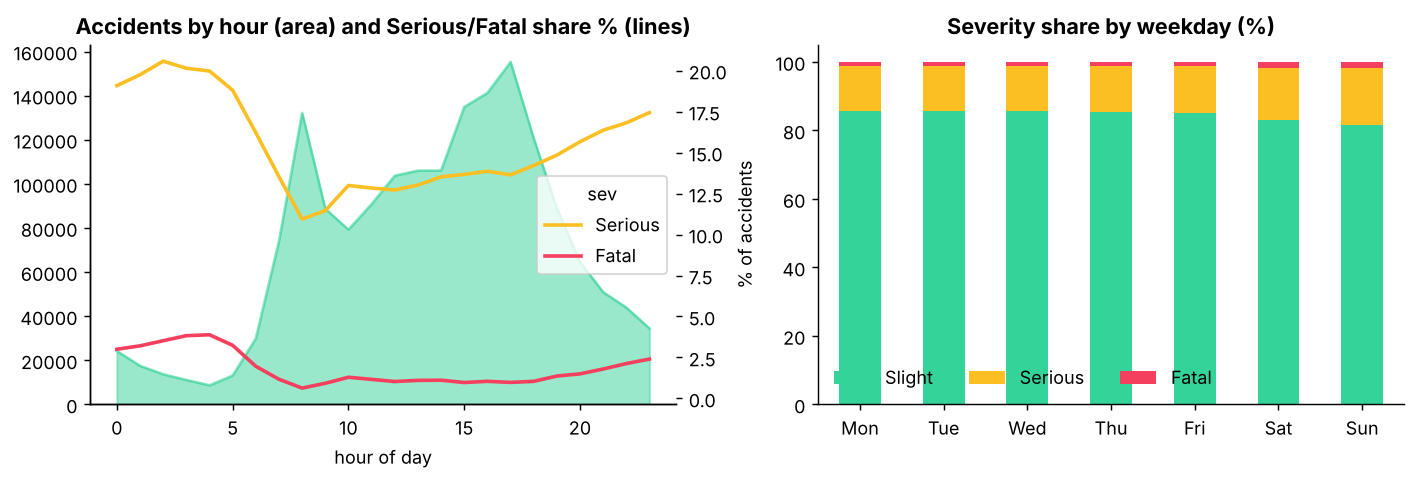

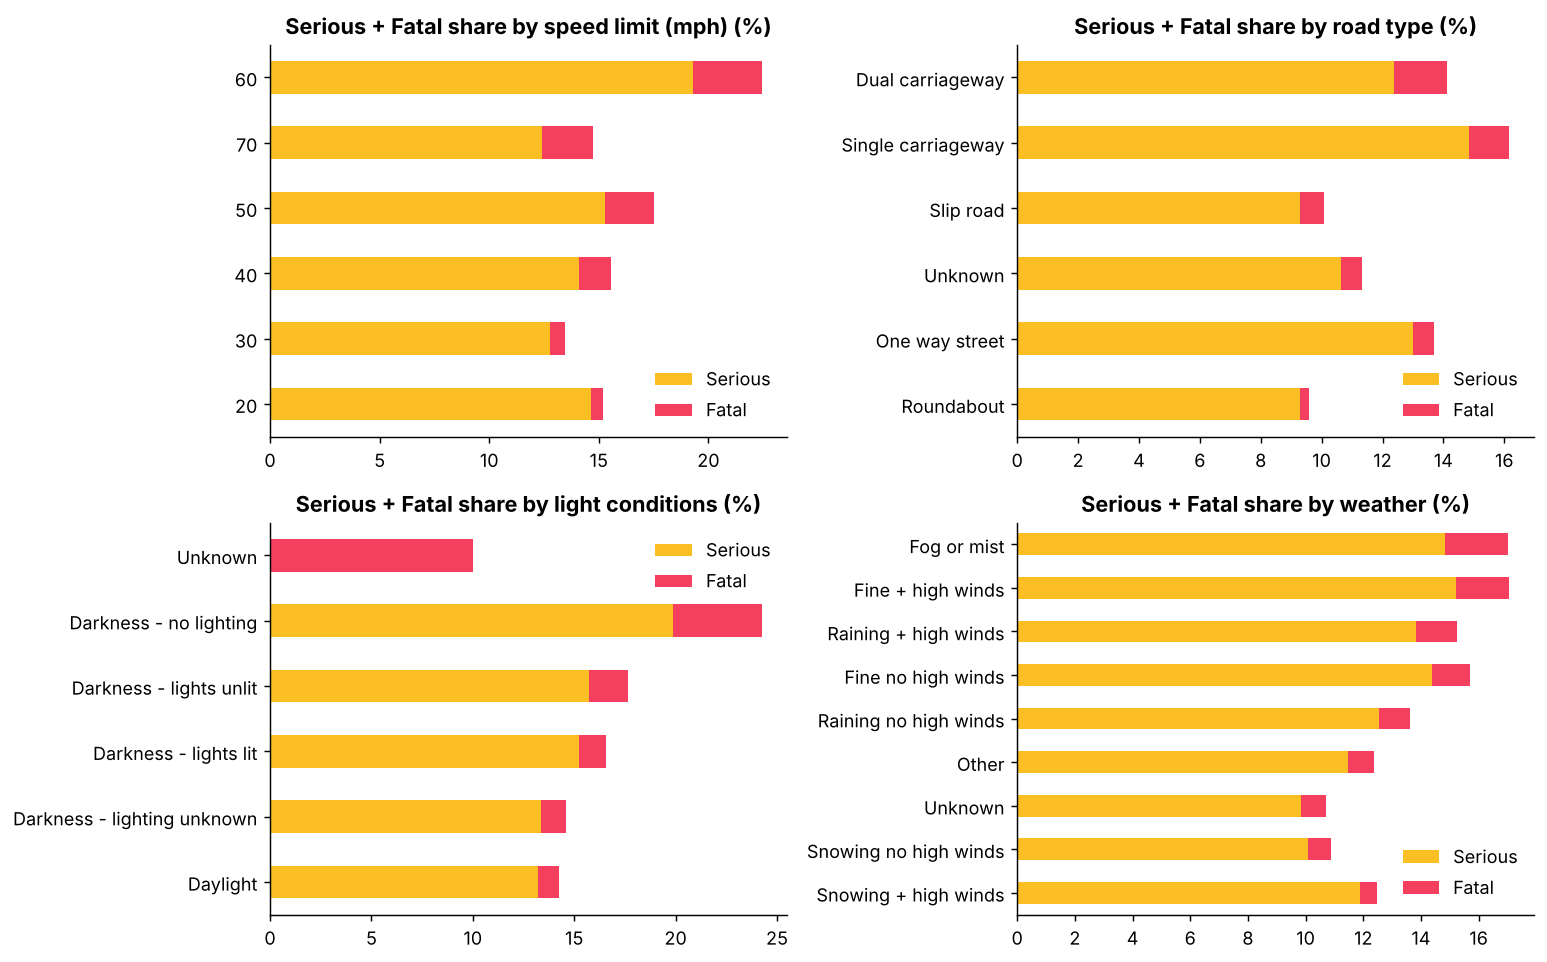

In [4]:
display(Image(F+'02_hour_weekday.png')); display(Image(F+'03_conditions.png'))

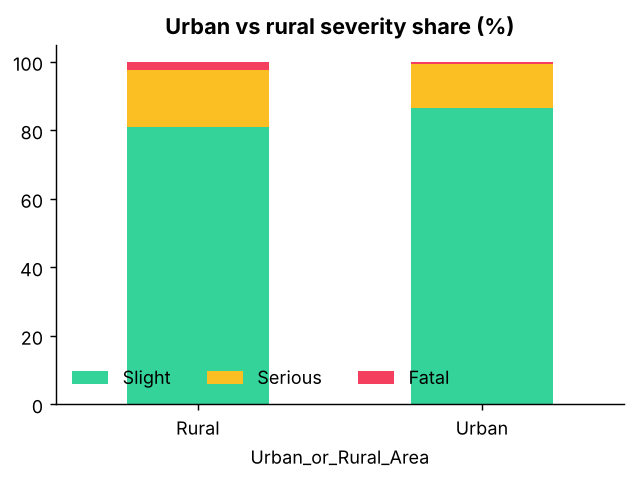

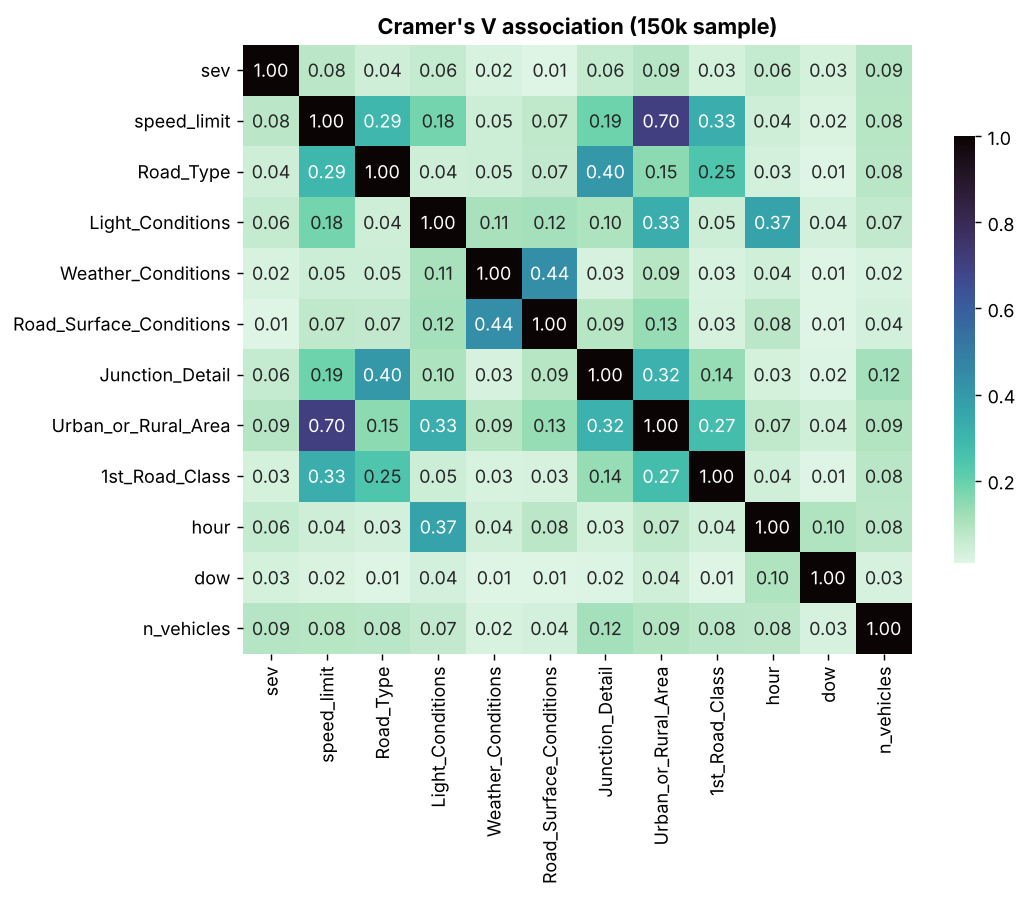

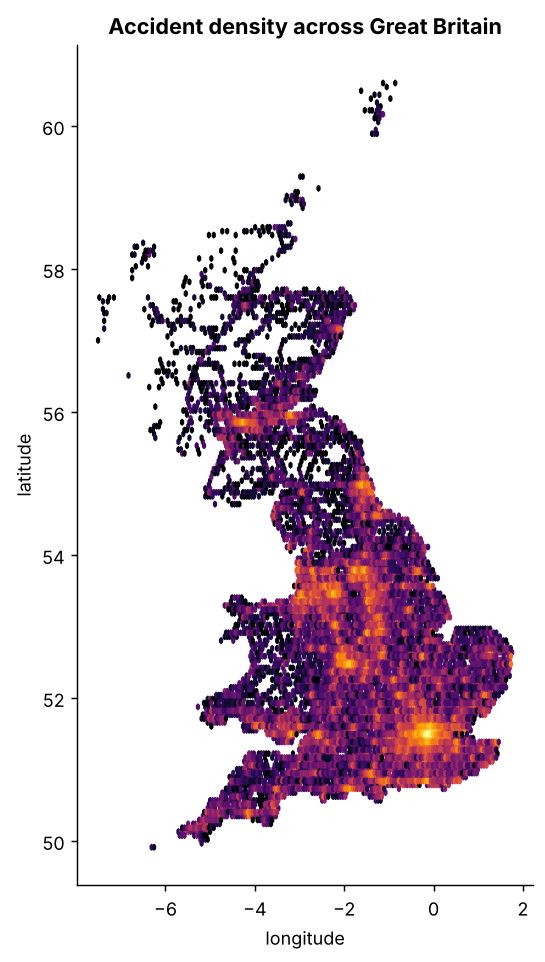

In [5]:
display(Image(F+'04_urban_rural.png')); display(Image(F+'07_cramers_v.png')); display(Image(F+'08_uk_density.png'))

## Leakage evidence
Casualty counts and police attendance are consequences of severity, so they are excluded.

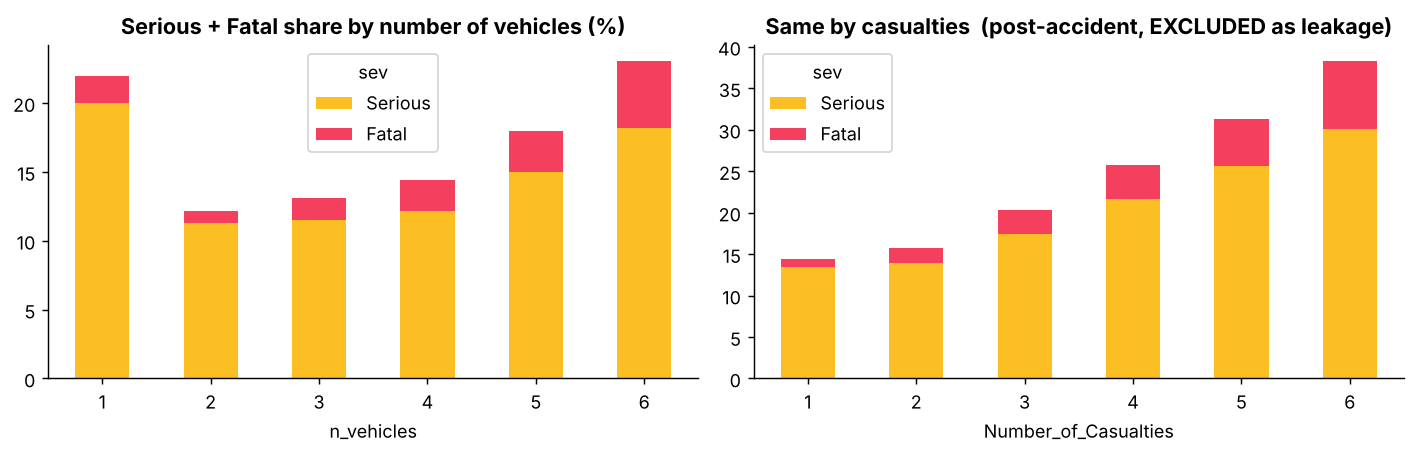

,feature,Fatal_rate_when_value_high,Fatal_rate_when_value_low
0,Number_of_Casualties,0.036754,0.009536
1,Did_Police_Officer_Attend_Scene_of_Accident,0.015704,0.001560


In [6]:
display(Image(F+'09_vehicles_casualties_leakage.png')); pd.read_csv(T+'leakage_evidence.csv')